# Import of libraries

In [21]:
import numpy as np #library to manipulate arrays
import matplotlib.pyplot as plt #library to plot figures
from PIL import Image
import cv2

# Conversion of images from png or jpg to bmp

In [22]:
image = Image.open("../Exemples_Images/PHENOCAM005_2019-09-23_11-16.jpg")
image.save("forest.bmp")
mask2 = Image.open("../Exemples_Images/PHENOCAM005_6_2019-09-27.png")
mask2.save("mask1.bmp")

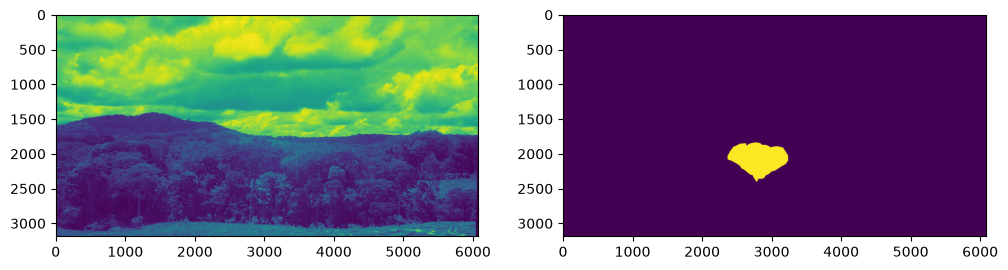

In [23]:
#Définition des dimensions de la figure en pouces (width, height)
plt.figure(figsize=(12, 5))

image_gris=image.convert("L")

plt.subplot(1, 2, 1)
plt.imshow(image_gris)

mask2_gris=mask2.convert("L")

plt.subplot(1, 2, 2)
plt.imshow(mask2_gris)

# RGB histogram calculation & average intensity

Nombre total de pixels dans la zone de la forêt : 303681
La valeur moyenne (m) pour le canal Rouge est : 38.962207052795534
La valeur moyenne (m) pour le canal Vert est : 39.516709968684246
La valeur moyenne (m) pour le canal Bleu est : 52.43163055969916


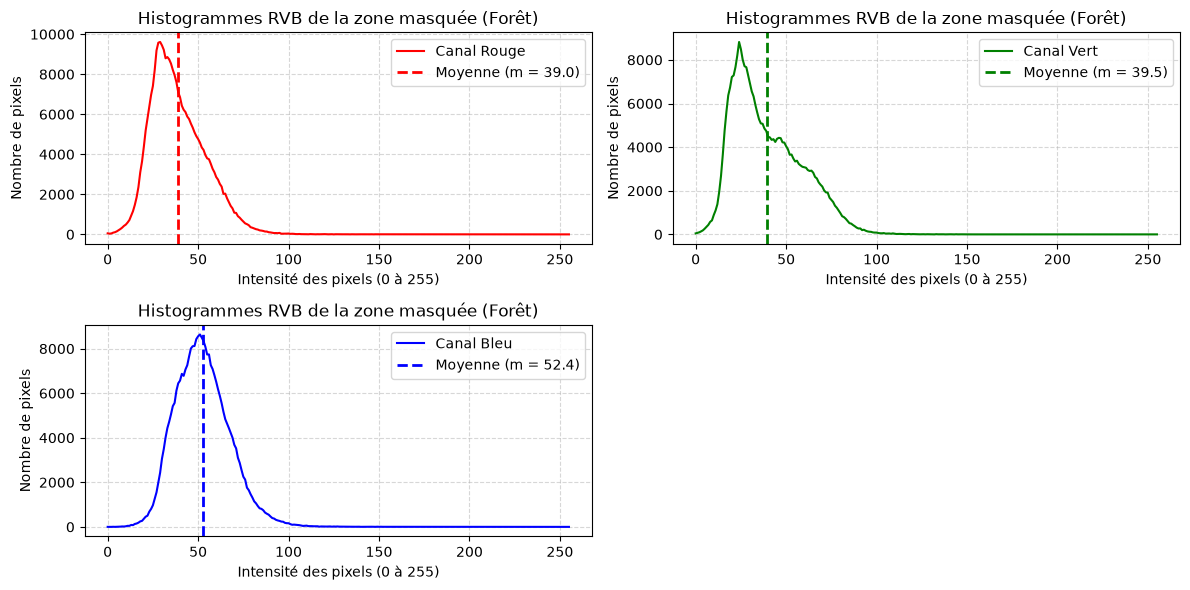

In [24]:
#1. Converting the image to color and to a NumPy array (RGB format if loaded with PIL)
img_color_np = np.array(image, dtype=np.uint8)
masque_np = np.array(mask2, dtype=np.uint8)

#2. Total number of pixels in the forest mask area (that's your \sum p_i)
NbsT_Pi = np.sum(masque_np > 0)
print(f"Nombre total de pixels dans la zone de la forêt : {NbsT_Pi}")

#3. Define the intensities (the x_i from 0 to 255)
# We ensure we have a vector of size 256 to multiply by the p_i
intensites = np.arange(256)

#4. Display color settings (Red, Green, Blue)
colors = ('r', 'g', 'b')
channel_names = ['Rouge', 'Vert', 'Bleu']
color_ch = ['red', 'green', 'blue']

#5. Initialize variables to store the mean values for each channel (Moy_R, Moy_G, Moy_B)
Moy_R = 0
Moy_G = 0
Moy_B = 0

plt.figure(figsize=(12, 6))

#6. Channel (0 for Red, 1 for Green, 2 for Blue)
for i, color in enumerate(colors):
  hist_canal = cv2.calcHist(
      images=[img_color_np],
      channels=[i],  # i = 0 (Red), 1 (Green), 2 (Blue)
      mask=masque_np,
      histSize=[256],
      ranges=[0, 255],
  )
  
  #7. Nbr_Pi_G is in the form of a 2D array (256, 1), we convert it to 1D using .flatten()
  p_i = hist_canal.flatten()

  #8. Calculating the sum of the products (p_i * x_i)
  somme_produits = np.sum(p_i * intensites)

  #9. Calculation of the final average (m)
  moyenne_m = somme_produits / NbsT_Pi

  #10. Recording the histogram in a CSV file
  np.savetxt(
    f"Hist_{i}.csv",
    np.asarray( hist_canal.flatten()),
    delimiter=",",
    fmt="%d",
    comments=""
  )
  #11. Storing the mean values for each channel
  if i == 0:
      Moy_R = moyenne_m
  elif i == 1:
      Moy_G = moyenne_m
  else:
      Moy_B = moyenne_m

  plt.subplot(2, 2, i + 1)
  plt.plot(hist_canal, color=color, label=f'Canal {channel_names[i]}')

  #12. Adding a vertical line to indicate the mean value on the histogram
  plt.axvline(x=moyenne_m, color=color_ch[i], linestyle='--', linewidth=2, label=f'Moyenne (m = {moyenne_m:.1f})')
  plt.title("Histogrammes RVB de la zone masquée (Forêt)")
  plt.xlabel("Intensité des pixels (0 à 255)")
  plt.ylabel("Nombre de pixels")
  plt.legend()
  plt.grid(True, linestyle="--", alpha=0.5)

#13. Displaying the mean values for each channel
print(f"La valeur moyenne (m) pour le canal Rouge est : {Moy_R}")
print(f"La valeur moyenne (m) pour le canal Vert est : {Moy_G}")
print(f"La valeur moyenne (m) pour le canal Bleu est : {Moy_B}")
plt.tight_layout()
plt.show()



# Calculation of the normalized average vegetation index (ExG)

L'indice ExG calculé à partir des moyennes est : -12.3604176751262


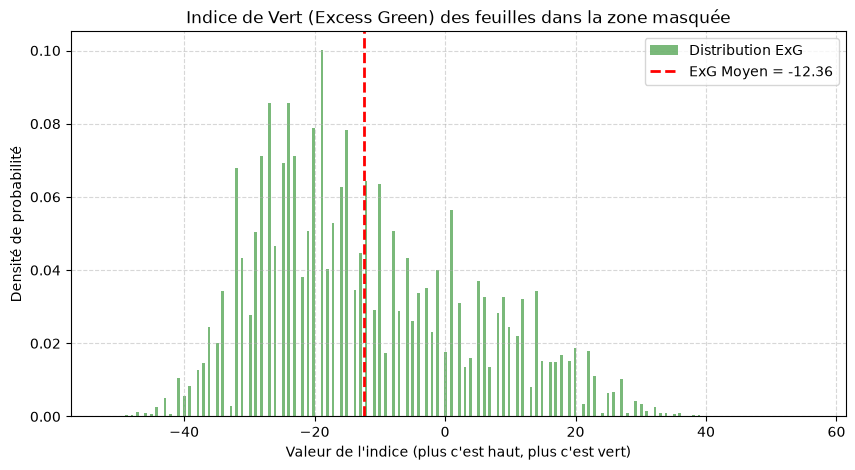

In [25]:
#1. Calculate the ExG for each pixel in the image (converting to float to avoid overflow)
R = img_color_np[:, :, 0].astype(float)
G = img_color_np[:, :, 1].astype(float)
B = img_color_np[:, :, 2].astype(float)
exg_image = (2 * G) - R - B

#2. Filter to keep only the pixels located under the forest mask
exg_foret = exg_image[masque_np > 0]

#3. Calculation of the ExG index from the channel means
ExG_moyen = (2 * Moy_G) - Moy_R - Moy_B

print(f"L'indice ExG calculé à partir des moyennes est : {ExG_moyen}")

#4. Display the histogram of the ExG values for the pixels under the forest mask
plt.figure(figsize=(10, 5))
plt.hist(exg_foret, bins=256, color='forestgreen', density=True, alpha=0.6, label='Distribution ExG')

#5. Add your global mean (ExG_moyen) as a red vertical line
plt.axvline(x=ExG_moyen, color='red', linestyle='--', linewidth=2, label=f'ExG Moyen = {ExG_moyen:.2f}')

plt.title("Indice de Vert (Excess Green) des feuilles dans la zone masquée")
plt.xlabel("Valeur de l'indice (plus c'est haut, plus c'est vert)")
plt.ylabel("Densité de probabilité")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()